### Why do EDA

- Model building
- Analysis and reporting
- Validate assumptions
- Handling missing values
- feature engineering
- detecting outliers

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


## Step 1: `LOAD THE DATA FROM SOURCE`

In [2]:
df = pd.read_csv('data/train.csv')
df


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
...,...,...,...,...,...,...,...,...,...,...,...,...
886,887,0,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.0000,NaN,S
887,888,1,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.0000,B42,S
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,2,W./C. 6607,23.4500,NaN,S
889,890,1,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.0000,C148,C


In [3]:
df.columns

Index(['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp',
       'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked'],
      dtype='str')

# Step 2
## Column Types

- **Numerical** - Age,Fare,PassengerId
- **Categorical** - Survived, Pclass, Sex, SibSp, Parch,Embarked
- **Mixed** - Name, Ticket, Cabin

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB


### Univariate Analysis 

Univariate analysis focuses on analyzing each feature in the dataset independently.

- **Distribution analysis**: The distribution of each feature is examined to identify its shape, central tendency, and dispersion.

- **Identifying potential issues**: Univariate analysis helps in identifying potential problems with the data such as outliers, skewness, and missing values

## Univariate Analysis
- Analyzes one feature/column at a time.
- Used to understand its distribution, central tendency, and dispersion.
- Helps detect outliers, skewness, and missing values.

## `Common Distribution Shapes`
- Normal: Symmetrical, bell-shaped; mean ≈ median ≈ mode.
- Skewed: Asymmetrical; can be right-skewed or left-skewed.
- Bimodal: Has two peaks.
- Uniform: Values have approximately equal frequency/probability.<br>
## `Univariate Analysis — Numerical Columns`
1. Descriptive Statistics: Mean, median, mode, std, range, quartiles.
2. Visualization: Histogram, box plot, density plot.
3. Outliers: Detect and decide whether they are errors or genuine values.
4. Skewness: Check distribution symmetry; transform if necessary.
5. Conclusion: Summarize findings and decide the next analysis steps.

### Age :
### *Conclusions* -
- Age column is normally(almost) distributed with a slight right skew.
- There are around 20% missing values.
- There is some outliers on right side.


In [5]:
df['Age'].describe()

count    714.000000
mean      29.699118
std       14.526497
min        0.420000
25%       20.125000
50%       28.000000
75%       38.000000
max       80.000000
Name: Age, dtype: float64

<Axes: ylabel='Frequency'>

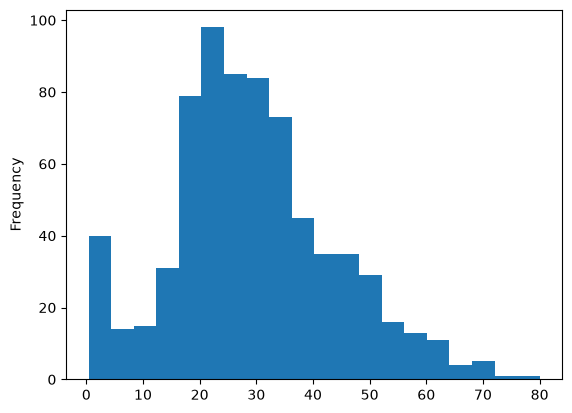

In [6]:
df['Age'].plot(kind='hist',bins=20)

<Axes: ylabel='Density'>

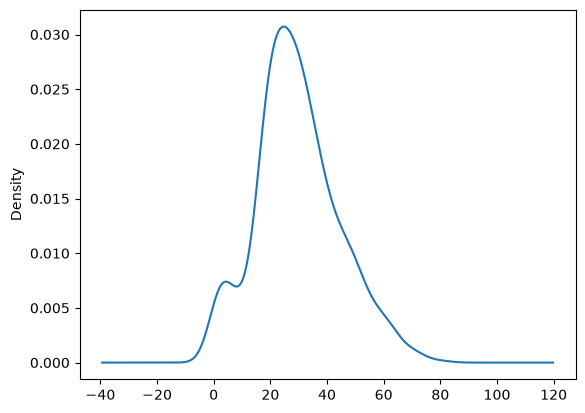

In [7]:
df['Age'].plot(kind='kde')

In [8]:
df['Age'].skew()

np.float64(0.38910778230082704)

nearly symmetric, slight right lean,

<Axes: >

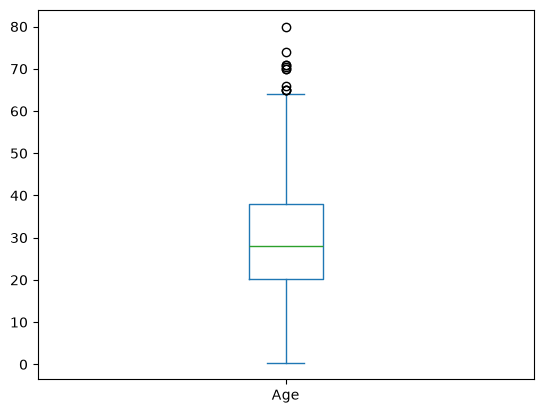

In [9]:
df['Age'].plot(kind='box')

In [10]:
df[df['Age'] > 65 ]

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
33,34,0,2,"Wheadon, Mr. Edward H",male,66.0,0,0,C.A. 24579,10.5000,NaN,S
96,97,0,1,"Goldschmidt, Mr. George B",male,71.0,0,0,PC 17754,34.6542,A5,C
116,117,0,3,"Connors, Mr. Patrick",male,70.5,0,0,370369,7.7500,NaN,Q
493,494,0,1,"Artagaveytia, Mr. Ramon",male,71.0,0,0,PC 17609,49.5042,NaN,C
630,631,1,1,"Barkworth, Mr. Algernon Henry Wilson",male,80.0,0,0,27042,30.0000,A23,S
672,673,0,2,"Mitchell, Mr. Henry Michael",male,70.0,0,0,C.A. 24580,10.5000,NaN,S
745,746,0,1,"Crosby, Capt. Edward Gifford",male,70.0,1,1,WE/P 5735,71.0000,B22,S
851,852,0,3,"Svensson, Mr. Johan",male,74.0,0,0,347060,7.7750,NaN,S


In [11]:
df['Age'].isnull().sum()/len(df['Age'])

np.float64(0.19865319865319866)

### Fare
### *Conclusions :*
- The data is highly(+ve) skewed .
- *Fare column contains groupfare and not the individual Fare .
- we need to create a new col named individual Fare.`(Feature Engg.)`

In [12]:
df['Fare'].describe()

count    891.000000
mean      32.204208
std       49.693429
min        0.000000
25%        7.910400
50%       14.454200
75%       31.000000
max      512.329200
Name: Fare, dtype: float64

In [13]:
df['Fare'].isnull().sum()

np.int64(0)

<Axes: ylabel='Frequency'>

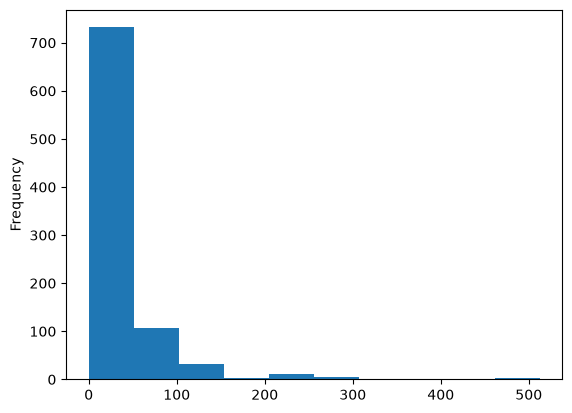

In [14]:
df['Fare'].plot(kind='hist')

In [15]:
# df['Age'].kurt()
df['Fare'].kurt()

np.float64(33.39814088089868)

<Axes: ylabel='Density'>

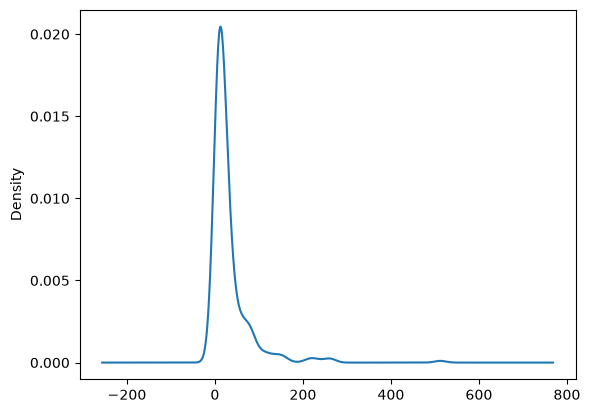

In [16]:
df['Fare'].plot(kind='kde')

In [17]:
df['Fare'].skew()

np.float64(4.787316519674893)

<Axes: >

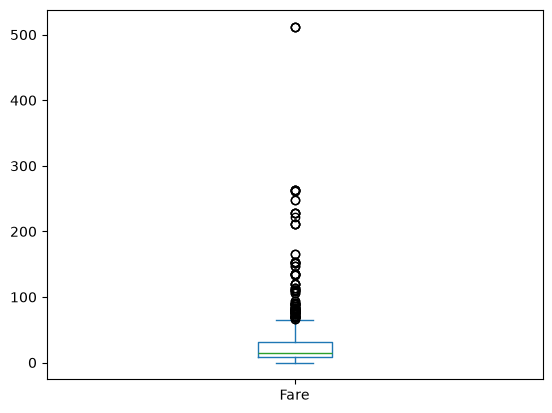

In [18]:
df['Fare'].plot(kind='box')

In [19]:
df[df['Fare'] > 200]

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
27,28,0,1,"Fortune, Mr. Charles Alexander",male,19.0,3,2,19950,263.0000,C23 C25 C27,S
88,89,1,1,"Fortune, Miss. Mabel Helen",female,23.0,3,2,19950,263.0000,C23 C25 C27,S
118,119,0,1,"Baxter, Mr. Quigg Edmond",male,24.0,0,1,PC 17558,247.5208,B58 B60,C
258,259,1,1,"Ward, Miss. Anna",female,35.0,0,0,PC 17755,512.3292,NaN,C
299,300,1,1,"Baxter, Mrs. James (Helene DeLaudeniere Chaput)",female,50.0,0,1,PC 17558,247.5208,B58 B60,C
311,312,1,1,"Ryerson, Miss. Emily Borie",female,18.0,2,2,PC 17608,262.3750,B57 B59 B63 B66,C
341,342,1,1,"Fortune, Miss. Alice Elizabeth",female,24.0,3,2,19950,263.0000,C23 C25 C27,S
377,378,0,1,"Widener, Mr. Harry Elkins",male,27.0,0,2,113503,211.5000,C82,C
380,381,1,1,"Bidois, Miss. Rosalie",female,42.0,0,0,PC 17757,227.5250,NaN,C
438,439,0,1,"Fortune, Mr. Mark",male,64.0,1,4,19950,263.0000,C23 C25 C27,S


### Steps of doing Univariate Analysis on Categorical columns

- **Descriptive Statistics**: Frequency distribution of each category.
- **Visualizations**: Count plots and pie charts to show category proportions.
- **Missing Values**: Check for missing values; decide whether to impute or exclude.
- **Conclusion**: Summarize findings and decide next steps.

## Survived 
## *conclusion:*
- It was a catastrophic disaster in which more than 50% of passengers could not survive**

In [20]:
df['Survived'].value_counts()

Survived
0    549
1    342
Name: count, dtype: int64

<Axes: title={'center': 'Survived'}>

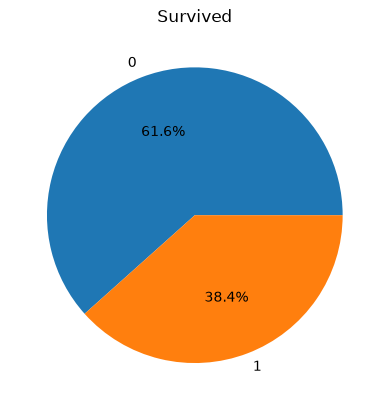

In [21]:
df['Survived'].value_counts().plot(kind='pie',autopct='%0.1f%%',title='Survived')

<Axes: xlabel='Survived'>

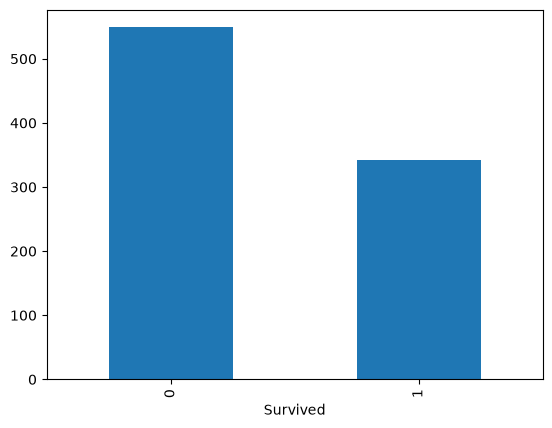

In [22]:
df['Survived'].value_counts().plot(kind='bar')

In [23]:
df['Survived'].isnull().sum()

np.int64(0)

## Pclass:
### **Conclusions:**
- Surprisingly less people are traveling in Pclass-2 compare to Pclass-1.

In [24]:
df['Pclass'].value_counts()

Pclass
3    491
1    216
2    184
Name: count, dtype: int64

<Axes: xlabel='Pclass'>

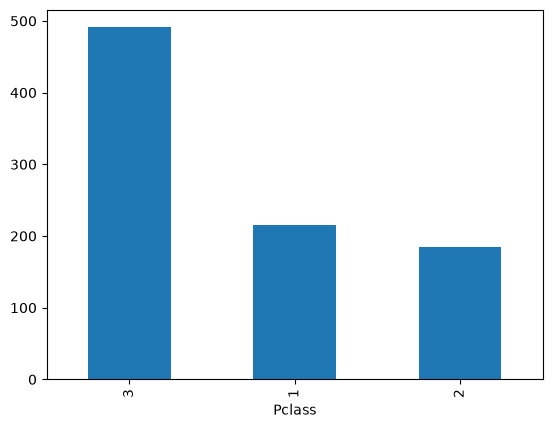

In [25]:
df['Pclass'].value_counts().plot(kind='bar')


<Axes: title={'center': 'Pclass'}>

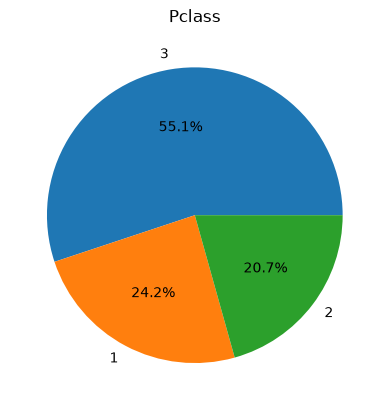

In [26]:
df['Pclass'].value_counts().plot(kind='pie',title='Pclass',autopct='%0.1f%%')

In [27]:
df['Pclass'].isnull().value_counts()

Pclass
False    891
Name: count, dtype: int64

## Sex
### **Conclusions:**
- There were more Men then women

(array([0, 1]), [Text(0, 0, 'male'), Text(1, 0, 'female')])

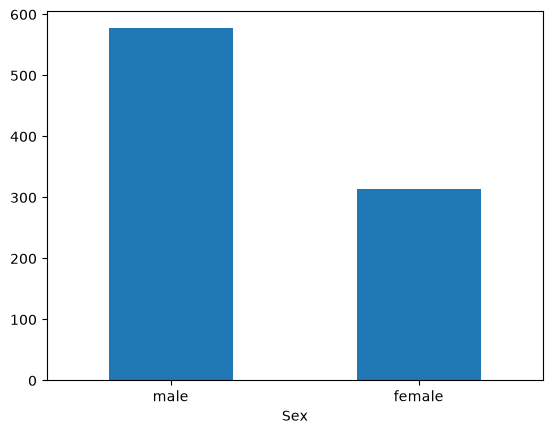

In [28]:
df['Sex'].value_counts().plot(kind='bar')
plt.xticks(rotation=0)

<Axes: >

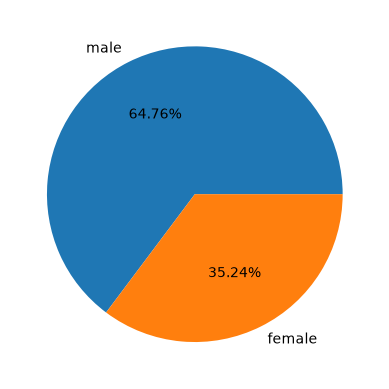

In [29]:
df['Sex'].value_counts().plot(kind='pie',autopct="%0.2f%%")

## Sibsp


In [30]:
df['SibSp'].value_counts()

SibSp
0    608
1    209
2     28
4     18
3     16
8      7
5      5
Name: count, dtype: int64

<Axes: xlabel='SibSp'>

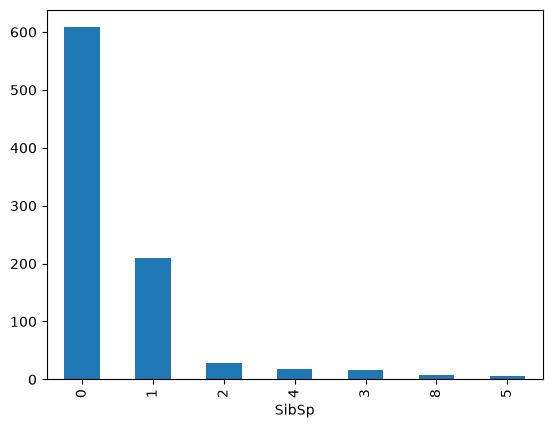

In [31]:
df['SibSp'].value_counts().plot(kind='bar')

<Axes: >

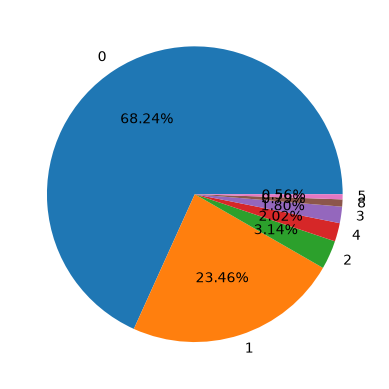

In [32]:
df['SibSp'].value_counts().plot(kind='pie',autopct="%0.2f%%")

## Parch

In [33]:
df['Parch'].value_counts()

Parch
0    678
1    118
2     80
5      5
3      5
4      4
6      1
Name: count, dtype: int64

<Axes: xlabel='Parch'>

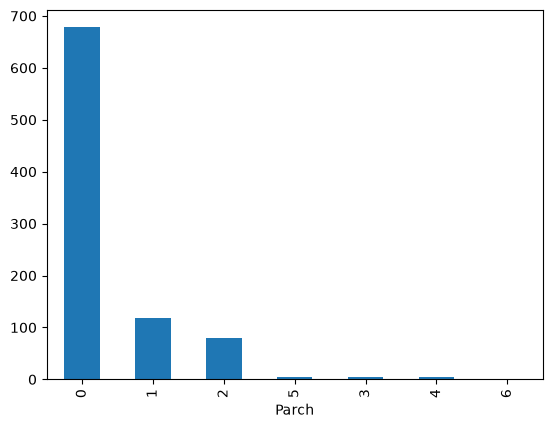

In [34]:
df['Parch'].value_counts().plot(kind='bar')

<Axes: >

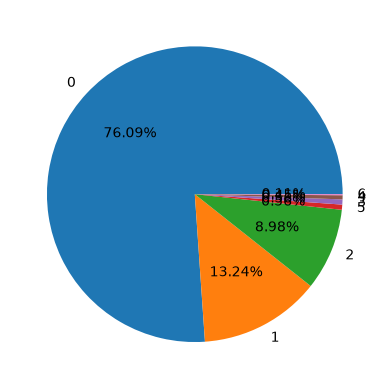

In [35]:
df['Parch'].value_counts().plot(kind='pie',autopct="%0.2f%%")

# Parch and Sibsp 
## conclusion: 
- Parch and SibSp cols can be merged to form  a new col call family_size
- Create a new col called is_alone

## Embarked

In [36]:
df['Embarked'].value_counts()

Embarked
S    644
C    168
Q     77
Name: count, dtype: int64

<Axes: xlabel='Embarked'>

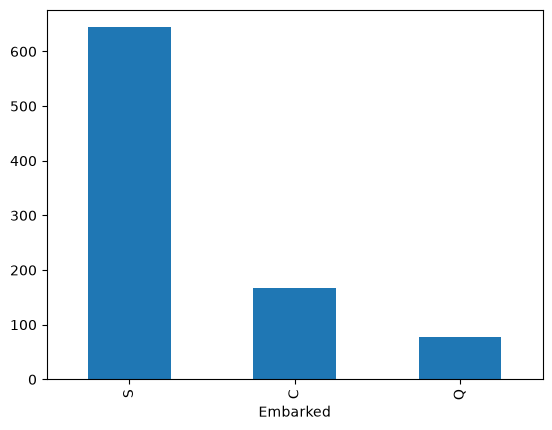

In [37]:
df['Embarked'].value_counts().plot(kind='bar')

<Axes: >

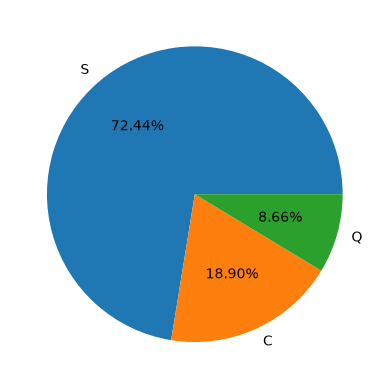

In [38]:
df['Embarked'].value_counts().plot(kind='pie',autopct="%0.2f%%")

### Steps of doing Bivariate Analysis

- Select 2 columns
- Identify the relationship type:
    1. `**Numerical – Numerical**`
       - Plots: scatterplot (regression plot), 2D histplot, 2D KDE plot
       - Check correlation coefficient for linear relationship
    2. `**Numerical – Categorical**`
       - Compare the numerical distribution across categories
       - Plots: barplot, boxplot, kdeplot, violinplot, scatterplot
    3. `**Categorical – Categorical**`
       - Use cross-tabulations/contingency tables to show value distribution across categories
       - Plots: heatmap, stacked barplot, treemap
- Write conclusions

- Traveling in Pclass-3 is very risky and in Pclass-1 is more safe.

In [39]:
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


## First categorical vs categorical 

In [40]:
pd.crosstab(df['Survived'],df['Pclass'],normalize='columns')*100

Pclass,1,2,3
Survived,,,
0,37.037037,52.717391,75.763747
1,62.962963,47.282609,24.236253


<Axes: xlabel='Pclass', ylabel='Survived'>

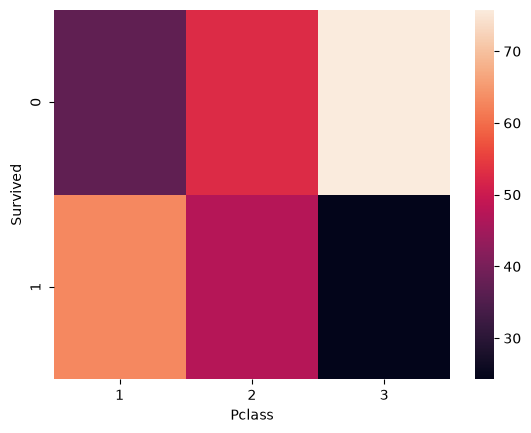

In [41]:
sns.heatmap(pd.crosstab(df['Survived'],df['Pclass'],normalize='columns')*100)

In [42]:
pd.crosstab(df['Survived'],df['Sex'],normalize='columns')*100

Sex,female,male
Survived,,
0,25.796178,81.109185
1,74.203822,18.890815


<Axes: xlabel='Sex', ylabel='Survived'>

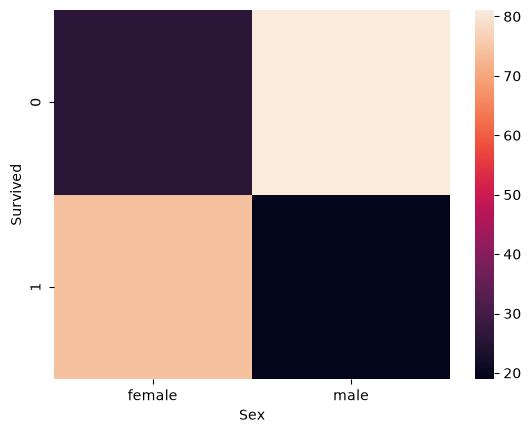

In [43]:
sns.heatmap(pd.crosstab(df['Survived'],df['Sex'],normalize='columns')*100)

In [44]:
pd.crosstab(df['Survived'],df['Embarked'],normalize='columns')*100

Embarked,C,Q,S
Survived,,,
0,44.642857,61.038961,66.304348
1,55.357143,38.961039,33.695652


<Axes: xlabel='Embarked', ylabel='Survived'>

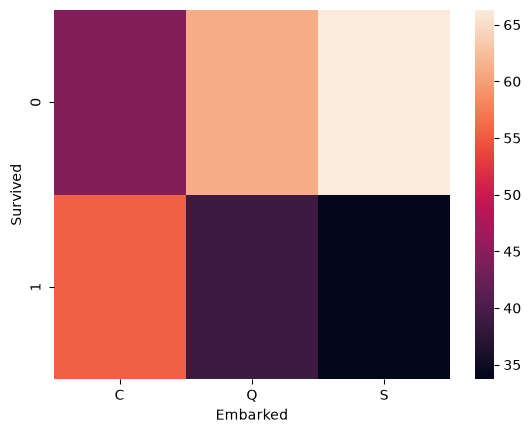

In [45]:
sns.heatmap(pd.crosstab(df['Survived'],df['Embarked'],normalize='columns')*100)

## Assumption 1 : for more Cherbourg city in Embarked column for Survived.
##  Comparison of Embarked with sex column 

In [46]:
pd.crosstab(df['Sex'],df['Embarked'],normalize='columns')*100

Embarked,C,Q,S
Sex,,,
female,43.452381,46.753247,31.521739
male,56.547619,53.246753,68.478261


## Assumption 2 : for more Cherbourg city in Embarked column for Survived.
##  Comparison of Embarked with Pclass column 

In [47]:
pd.crosstab(df['Pclass'],df['Embarked'],normalize='columns')*100

Embarked,C,Q,S
Pclass,,,
1,50.595238,2.597403,19.720497
2,10.119048,3.896104,25.465839
3,39.285714,93.506494,54.813665


# Assumption-2 got right there were more people in Pclass-1 from Cherbourg. This is the reason for more survived people from cherbourg

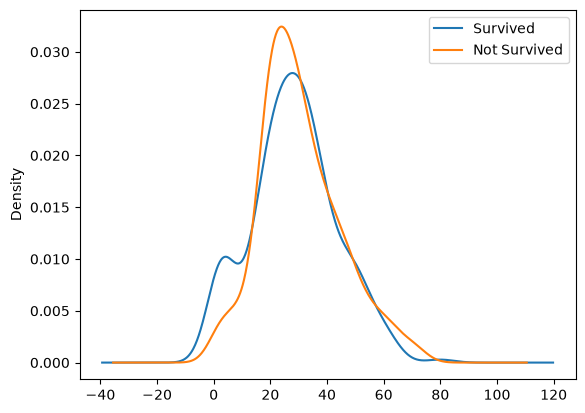

In [48]:
df[df['Survived'] == 1]['Age'].plot(kind='kde',label='Survived')
df[df['Survived'] == 0]['Age'].plot(kind='kde',label='Not Survived')

plt.legend()
plt.show()

In [49]:
df[df['Pclass'] == 1]['Age'].mean()

np.float64(38.233440860215055)

# Feature Engineering on Fare col

In [50]:
df['SibSp'].value_counts()

SibSp
0    608
1    209
2     28
4     18
3     16
8      7
5      5
Name: count, dtype: int64

In [51]:
df[df['Name'].str.contains('Sage')]

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
159,160,0,3,"Sage, Master. Thomas Henry",male,NaN,8,2,CA. 2343,69.55,NaN,S
180,181,0,3,"Sage, Miss. Constance Gladys",female,NaN,8,2,CA. 2343,69.55,NaN,S
201,202,0,3,"Sage, Mr. Frederick",male,NaN,8,2,CA. 2343,69.55,NaN,S
324,325,0,3,"Sage, Mr. George John Jr",male,NaN,8,2,CA. 2343,69.55,NaN,S
641,642,1,1,"Sagesser, Mlle. Emma",female,24.0,0,0,PC 17477,69.30,B35,C
792,793,0,3,"Sage, Miss. Stella Anna",female,NaN,8,2,CA. 2343,69.55,NaN,S
846,847,0,3,"Sage, Mr. Douglas Bullen",male,NaN,8,2,CA. 2343,69.55,NaN,S
863,864,0,3,"Sage, Miss. Dorothy Edith ""Dolly""",female,NaN,8,2,CA. 2343,69.55,NaN,S


In [52]:
df1=pd.read_csv('data/test.csv')

In [53]:
df = pd.concat([df,df1],ignore_index=True)
df


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0.0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1.0,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1.0,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1.0,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0.0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
...,...,...,...,...,...,...,...,...,...,...,...,...
1304,1305,NaN,3,"Spector, Mr. Woolf",male,NaN,0,0,A.5. 3236,8.0500,NaN,S
1305,1306,NaN,1,"Oliva y Ocana, Dona. Fermina",female,39.0,0,0,PC 17758,108.9000,C105,C
1306,1307,NaN,3,"Saether, Mr. Simon Sivertsen",male,38.5,0,0,SOTON/O.Q. 3101262,7.2500,NaN,S
1307,1308,NaN,3,"Ware, Mr. Frederick",male,NaN,0,0,359309,8.0500,NaN,S


In [54]:
df[df['Ticket'] == 'CA. 2343']

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
159,160,0.0,3,"Sage, Master. Thomas Henry",male,NaN,8,2,CA. 2343,69.55,NaN,S
180,181,0.0,3,"Sage, Miss. Constance Gladys",female,NaN,8,2,CA. 2343,69.55,NaN,S
201,202,0.0,3,"Sage, Mr. Frederick",male,NaN,8,2,CA. 2343,69.55,NaN,S
324,325,0.0,3,"Sage, Mr. George John Jr",male,NaN,8,2,CA. 2343,69.55,NaN,S
792,793,0.0,3,"Sage, Miss. Stella Anna",female,NaN,8,2,CA. 2343,69.55,NaN,S
846,847,0.0,3,"Sage, Mr. Douglas Bullen",male,NaN,8,2,CA. 2343,69.55,NaN,S
863,864,0.0,3,"Sage, Miss. Dorothy Edith ""Dolly""",female,NaN,8,2,CA. 2343,69.55,NaN,S
1079,1080,NaN,3,"Sage, Miss. Ada",female,NaN,8,2,CA. 2343,69.55,NaN,S
1233,1234,NaN,3,"Sage, Mr. John George",male,NaN,1,9,CA. 2343,69.55,NaN,S
1251,1252,NaN,3,"Sage, Master. William Henry",male,14.5,8,2,CA. 2343,69.55,NaN,S


In [55]:
df['Ticket'].value_counts()

Ticket
CA. 2343              11
CA 2144                8
1601                   8
347082                 7
347077                 7
                      ..
365237                 1
347086                 1
A.5. 3236              1
SOTON/O.Q. 3101262     1
359309                 1
Name: count, Length: 929, dtype: int64

In [56]:
df[df['Ticket'] == 'CA 2144']

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
59,60,0.0,3,"Goodwin, Master. William Frederick",male,11.0,5,2,CA 2144,46.9,NaN,S
71,72,0.0,3,"Goodwin, Miss. Lillian Amy",female,16.0,5,2,CA 2144,46.9,NaN,S
386,387,0.0,3,"Goodwin, Master. Sidney Leonard",male,1.0,5,2,CA 2144,46.9,NaN,S
480,481,0.0,3,"Goodwin, Master. Harold Victor",male,9.0,5,2,CA 2144,46.9,NaN,S
678,679,0.0,3,"Goodwin, Mrs. Frederick (Augusta Tyler)",female,43.0,1,6,CA 2144,46.9,NaN,S
683,684,0.0,3,"Goodwin, Mr. Charles Edward",male,14.0,5,2,CA 2144,46.9,NaN,S
1030,1031,NaN,3,"Goodwin, Mr. Charles Frederick",male,40.0,1,6,CA 2144,46.9,NaN,S
1031,1032,NaN,3,"Goodwin, Miss. Jessie Allis",female,10.0,5,2,CA 2144,46.9,NaN,S


In [57]:
df[df['Ticket'] == '347077']

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
25,26,1.0,3,"Asplund, Mrs. Carl Oscar (Selma Augusta Emilia...",female,38.0,1,5,347077,31.3875,NaN,S
182,183,0.0,3,"Asplund, Master. Clarence Gustaf Hugo",male,9.0,4,2,347077,31.3875,NaN,S
233,234,1.0,3,"Asplund, Miss. Lillian Gertrud",female,5.0,4,2,347077,31.3875,NaN,S
261,262,1.0,3,"Asplund, Master. Edvin Rojj Felix",male,3.0,4,2,347077,31.3875,NaN,S
1045,1046,NaN,3,"Asplund, Master. Filip Oscar",male,13.0,4,2,347077,31.3875,NaN,S
1065,1066,NaN,3,"Asplund, Mr. Carl Oscar Vilhelm Gustafsson",male,40.0,1,5,347077,31.3875,NaN,S
1270,1271,NaN,3,"Asplund, Master. Carl Edgar",male,5.0,4,2,347077,31.3875,NaN,S


## #Feature Engineering 
- making new and essential columns 


In [58]:
df['individual_fare'] = df['Fare']/(df['SibSp']+df['Parch']+1)


In [59]:
df[['individual_fare','Fare']].describe()

,individual_fare,Fare
count,1308.000000,1308.000000
mean,20.518215,33.295479
std,35.774337,51.758668
min,0.000000,0.000000
25%,7.452767,7.895800
50%,8.512483,14.454200
75%,24.237500,31.275000
max,512.329200,512.329200


In [60]:
df[df['individual_fare'] > 250]

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,individual_fare
258,259,1.0,1,"Ward, Miss. Anna",female,35.0,0,0,PC 17755,512.3292,NaN,C,512.3292
679,680,1.0,1,"Cardeza, Mr. Thomas Drake Martinez",male,36.0,0,1,PC 17755,512.3292,B51 B53 B55,C,256.1646
737,738,1.0,1,"Lesurer, Mr. Gustave J",male,35.0,0,0,PC 17755,512.3292,B101,C,512.3292
950,951,NaN,1,"Chaudanson, Miss. Victorine",female,36.0,0,0,PC 17608,262.3750,B61,C,262.3750
1234,1235,NaN,1,"Cardeza, Mrs. James Warburton Martinez (Charlo...",female,58.0,0,1,PC 17755,512.3292,B51 B53 B55,C,256.1646
1266,1267,NaN,1,"Bowen, Miss. Grace Scott",female,45.0,0,0,PC 17608,262.3750,NaN,C,262.3750


In [61]:
df['Family_size'] = df['SibSp'] + df['Parch'] + 1

In [62]:
# family_type
# 1   ->  alone
# 2-4 ->  small
# >5  ->  large

def transform_type(num):
    if num == 1:
        return 'alone'
    elif num > 1 and num < 5 :
        return 'small'
    else :
        return 'large'

In [63]:
df['family_type'] = df['Family_size'].apply(transform_type)
df

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,individual_fare,Family_size,family_type
0,1,0.0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S,3.625000,2,small
1,2,1.0,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C,35.641650,2,small
2,3,1.0,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S,7.925000,1,alone
3,4,1.0,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S,26.550000,2,small
4,5,0.0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S,8.050000,1,alone
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1304,1305,NaN,3,"Spector, Mr. Woolf",male,NaN,0,0,A.5. 3236,8.0500,NaN,S,8.050000,1,alone
1305,1306,NaN,1,"Oliva y Ocana, Dona. Fermina",female,39.0,0,0,PC 17758,108.9000,C105,C,108.900000,1,alone
1306,1307,NaN,3,"Saether, Mr. Simon Sivertsen",male,38.5,0,0,SOTON/O.Q. 3101262,7.2500,NaN,S,7.250000,1,alone
1307,1308,NaN,3,"Ware, Mr. Frederick",male,NaN,0,0,359309,8.0500,NaN,S,8.050000,1,alone


In [64]:
df['Survived'].isnull().value_counts()

Survived
False    891
True     418
Name: count, dtype: int64

In [65]:
pd.crosstab(df['Survived'],df['family_type'],normalize='columns')*100
# df['Survived'].value_counts()

family_type,alone,large,small
Survived,,,
0.0,69.646182,83.870968,42.123288
1.0,30.353818,16.129032,57.876712


In [66]:
df['family_type'].isnull().value_counts()

family_type
False    1309
Name: count, dtype: int64

In [67]:
df['surename'] = df['Name'].str.split(",").str.get(0)

In [68]:
df['title'] = df['Name'].str.split(',').str.get(1).str.strip(' ').str.split(' ').str.get(0)
df['title'].value_counts()

title
Mr.          757
Miss.        260
Mrs.         197
Master.       61
Rev.           8
Dr.            8
Col.           4
Ms.            2
Major.         2
Mlle.          2
Don.           1
Mme.           1
Lady.          1
Sir.           1
Capt.          1
the            1
Jonkheer.      1
Dona.          1
Name: count, dtype: int64

In [69]:
titles = ['Rev.', 'Dr.', 'Col.', 'Major.', 'Capt.', 'the', 'Jonkheer.']

df.loc[df['title'].isin(titles), 'title'] = 'other'

In [70]:
df['title'].value_counts()

title
Mr.        757
Miss.      260
Mrs.       197
Master.     61
other       25
Ms.          2
Mlle.        2
Don.         1
Mme.         1
Lady.        1
Sir.         1
Dona.        1
Name: count, dtype: int64

In [71]:
temp_df = df[df['title'].isin(['Mr.','Miss.','Mrs.','Master','other'])]


In [72]:
pd.crosstab(temp_df['Survived'],temp_df['title'],normalize='columns')*100

title,Miss.,Mr.,Mrs.,other
Survived,,,,
0.0,30.21978,84.332689,20.8,70.0
1.0,69.78022,15.667311,79.2,30.0


In [73]:
df['Cabin'].isnull().sum()/len(df['Cabin'])*100

np.float64(77.46371275783041)

In [74]:
df['Cabin'].value_counts().head(15)

Cabin
C23 C25 C27        6
G6                 5
B57 B59 B63 B66    5
F33                4
F2                 4
F4                 4
C78                4
D                  4
C22 C26            4
B96 B98            4
B58 B60            3
E101               3
E34                3
A34                3
C101               3
Name: count, dtype: int64

In [75]:
df['Cabin'] = df['Cabin'].fillna('M')


In [76]:
df['Cabin'].value_counts()

Cabin
M                  1014
C23 C25 C27           6
G6                    5
B57 B59 B63 B66       5
F33                   4
                   ... 
C39                   1
B24                   1
D40                   1
D38                   1
C105                  1
Name: count, Length: 187, dtype: int64

In [77]:
df['deck'] = df['Cabin'].str[0]

In [78]:
pd.crosstab(df['Pclass'],df['deck'])

deck,A,B,C,D,E,F,G,M,T
Pclass,,,,,,,,,
1,22,65,94,40,34,0,0,67,1
2,0,0,0,6,4,13,0,254,0
3,0,0,0,0,3,8,5,693,0


In [79]:
pd.crosstab(df['Survived'],df['deck'],normalize='columns')*100

deck,A,B,C,D,E,F,G,M,T
Survived,,,,,,,,,
0.0,53.333333,25.531915,40.677966,24.242424,25.0,38.461538,50.0,70.014556,100.0
1.0,46.666667,74.468085,59.322034,75.757576,75.0,61.538462,50.0,29.985444,0.0


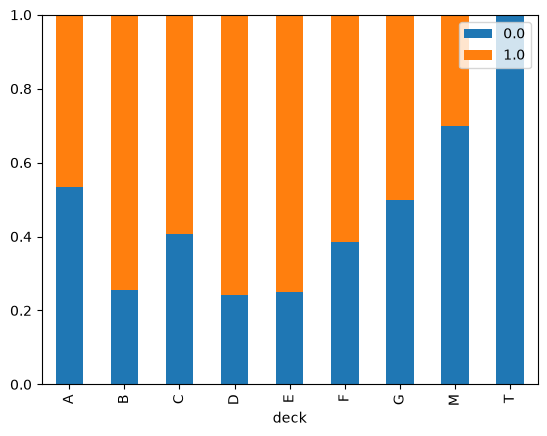

In [80]:
pd.crosstab(df['deck'],df['Survived'],normalize='index').plot(kind='bar',stacked=True).legend(loc='upper right')

## Multivariate Analysis :

<Axes: >

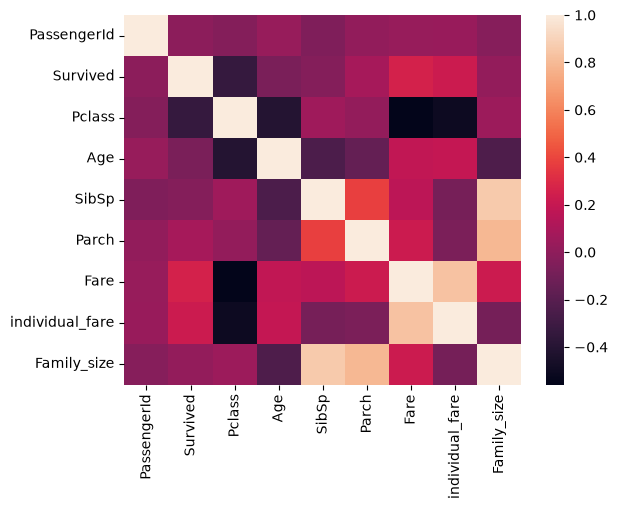

In [81]:
sns.heatmap(df.corr(numeric_only=True))

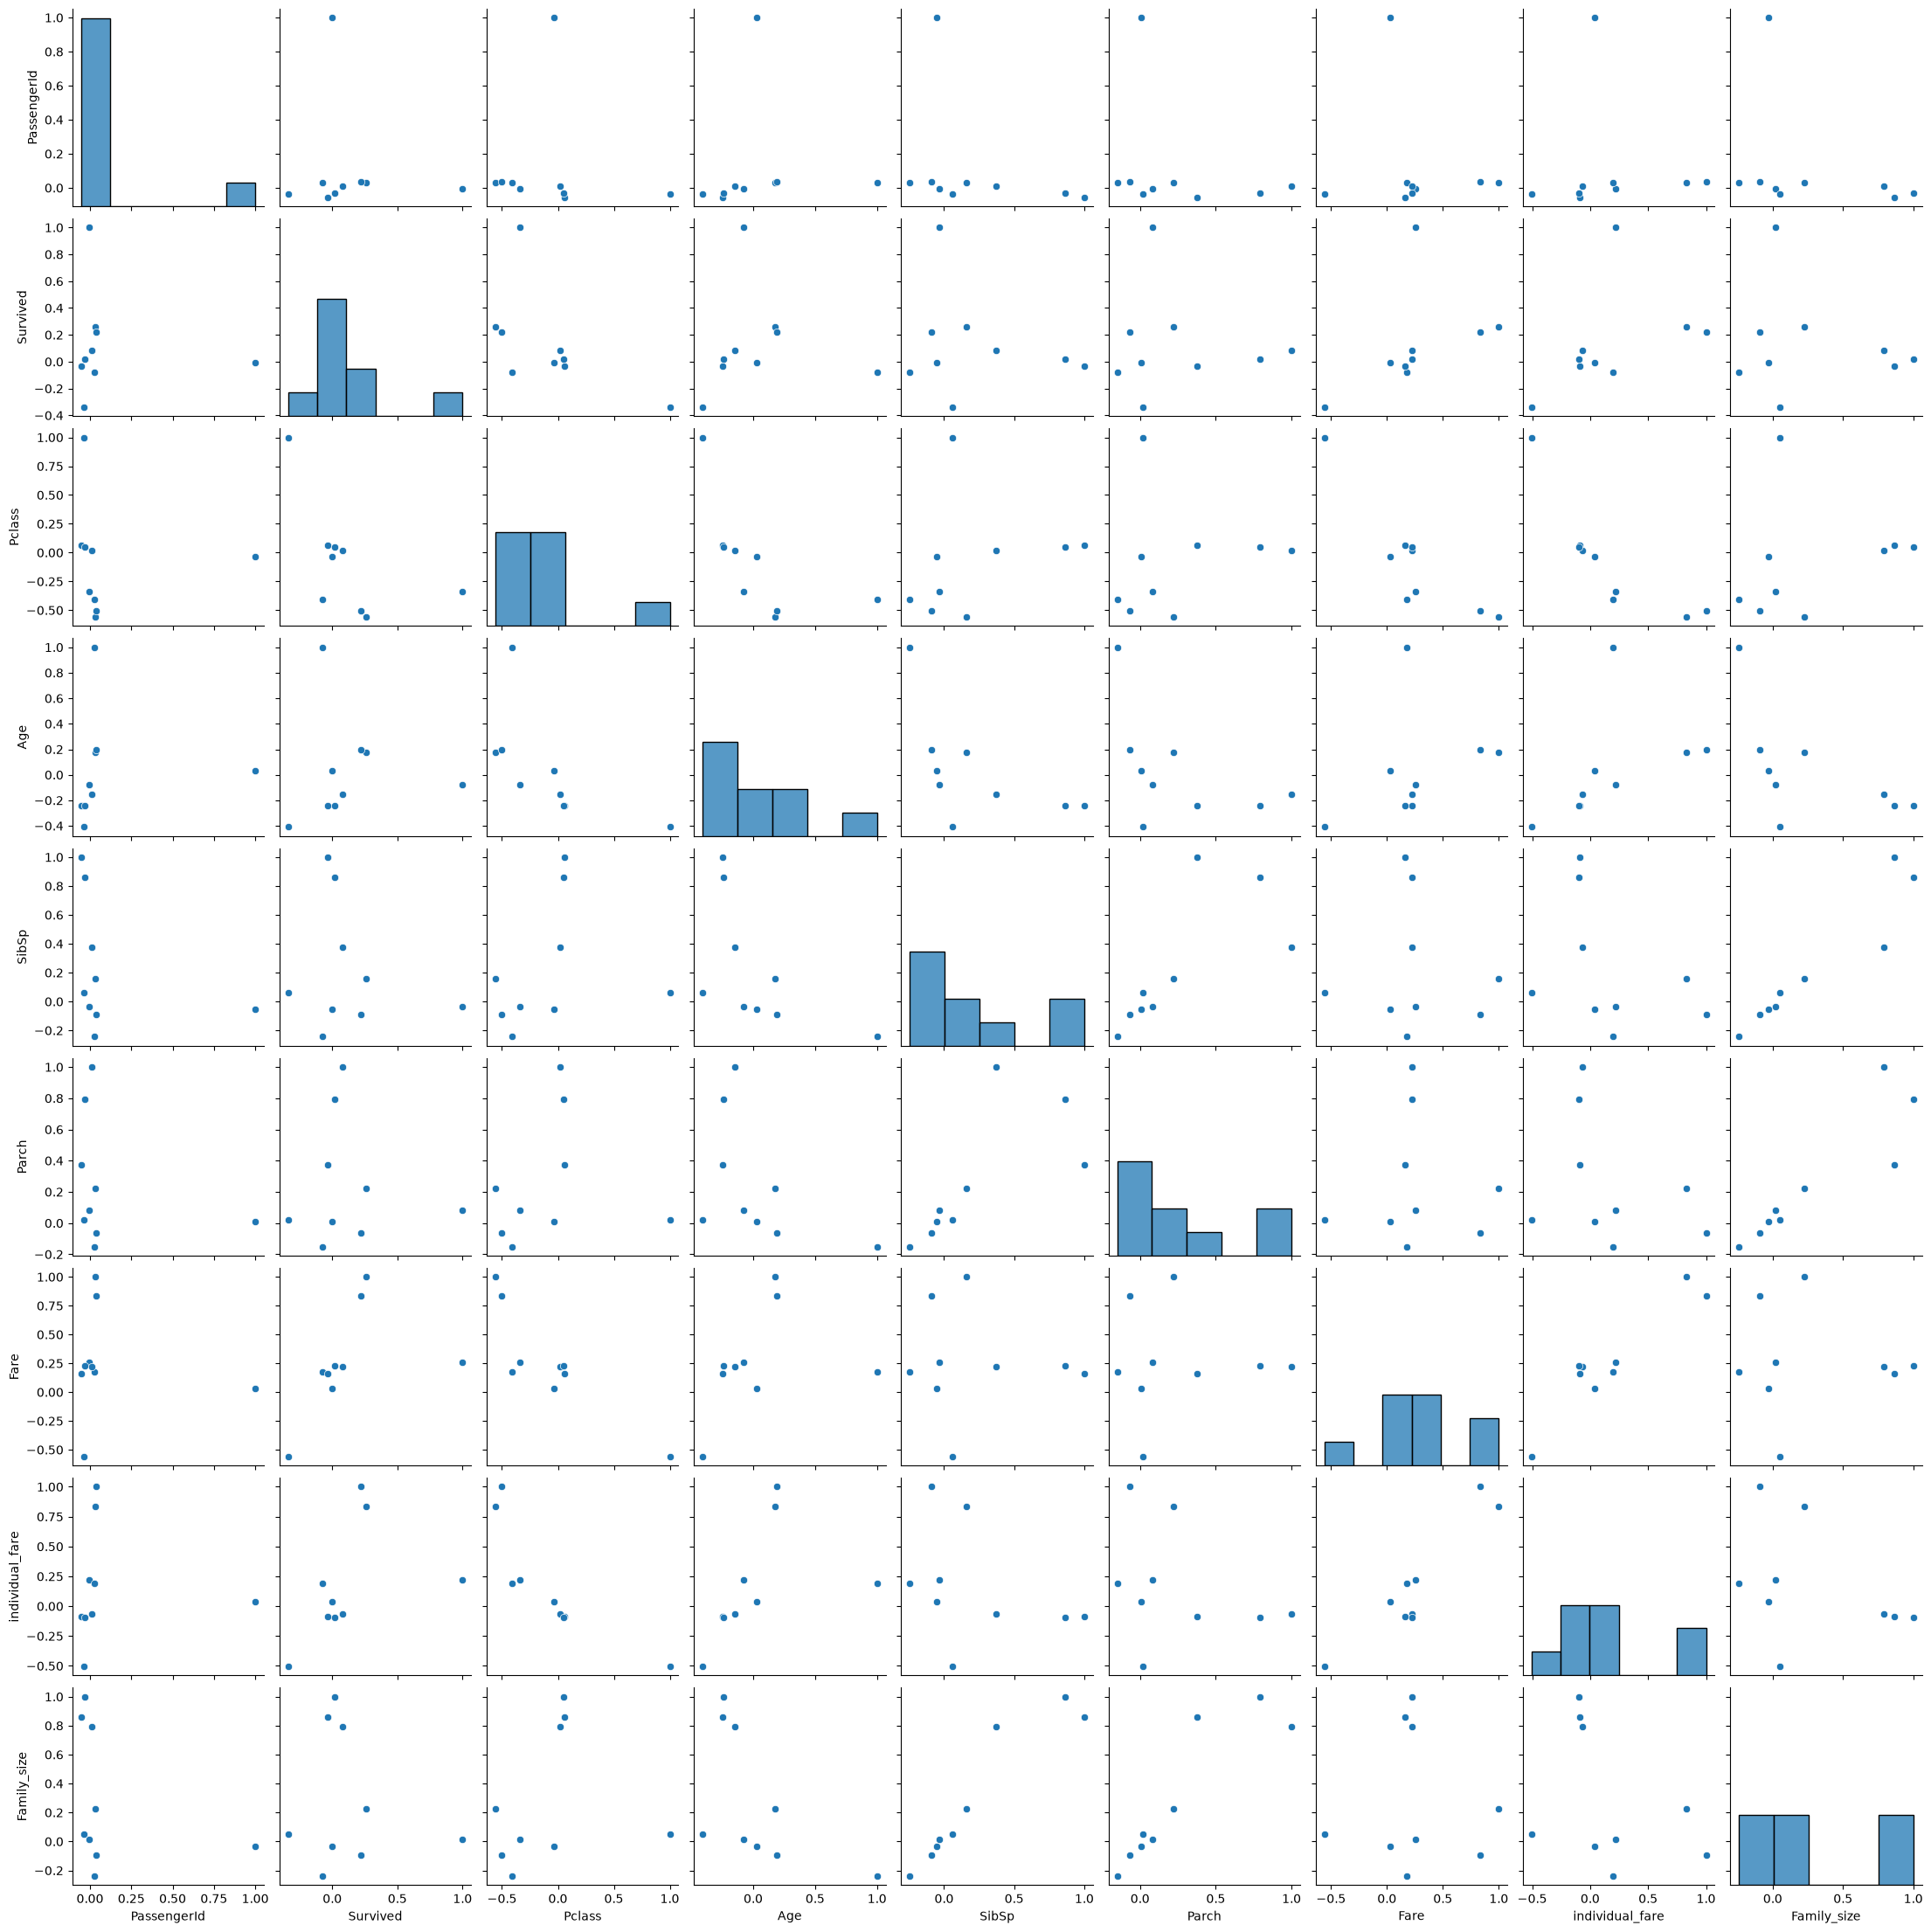

In [82]:
sns.pairplot(df.corr(numeric_only=True))

In [83]:
df.groupby(['Pclass', 'Sex'])['Survived'].mean()


Pclass  Sex   
1       female    0.968085
        male      0.368852
2       female    0.921053
        male      0.157407
3       female    0.500000
        male      0.135447
Name: Survived, dtype: float64

In [84]:
df.groupby(['Pclass', 'Sex'])['Survived'].count()  
df.groupby(['Pclass', 'Sex'])['Survived'].sum() 
df.groupby(['Pclass', 'Sex'])['Survived'].size()   

Pclass  Sex   
1       female    144
        male      179
2       female    106
        male      171
3       female    216
        male      493
Name: Survived, dtype: int64